In [1]:
import sys
import os
from pathlib import Path
sys.path.insert(0, os.path.abspath("..")) 

from pathlib import Path
import ast

from collections import Counter
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from sklearn.ensemble import RandomForestRegressor
import shap

from bench.datasets import load_dataset

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})

/Users/mamdouh/miniconda3/envs/bench/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ROOT_DIR = Path.cwd().parent

def load_ids(path):
    with open(path, "r") as f:
        return [int(i) for i in f.read().splitlines()]

small_ids  = load_ids(ROOT_DIR / "small_ids.txt")
normal_ids = load_ids(ROOT_DIR / "normal_ids.txt")
big_ids    = load_ids(ROOT_DIR / "big_ids.txt")
#load the dataset
df = pd.read_csv(ROOT_DIR / "data" / "meta_dataset.csv")
df_big = df[df["did"].isin(big_ids)]
df_normal = df[df["did"].isin(normal_ids)]
df_small = df[df["did"].isin(small_ids)]


In [3]:
#Run to get the imbalanced dataasets ids 
IMBALANCE_THRESH = 0.75

def entropy(labels):
    n = len(labels)
    k = len(set(labels))
    raw = -sum((c / n) * math.log2(c / n) for c in Counter(labels).values())
    return raw / math.log2(k) if k > 1 else 0.0

entropies = {}
for id in small_ids + normal_ids + big_ids:
    X, y = load_dataset(id)
    entropies[id] = entropy(y)

imbalanced_ids = []

for k, v in entropies.items():
    if v < IMBALANCE_THRESH:
        imbalanced_ids.append(k)   

df_imbalanced = df[df["did"].isin(imbalanced_ids)]

In [4]:
def get_agg_df(df):
    df = df.sort_values(["run_id", "seed"])
    df["time_per_seed"] = df.groupby("run_id")["time_taken"].diff().fillna(df["time_taken"])
    df["time_taken"] = df["time_per_seed"]

    # Aggregate across seeds
    group_keys  = ["did", "algo", "run_id", "config_number"]
    metric_cols = [c for c in df.columns if c.startswith("metrics.")] + ["time_taken"]
    keep_cols   = [c for c in df.columns if c.startswith("config.")] + ["result_file"]

    agg_spec = {}
    for c in metric_cols:
        agg_spec[f"{c}_mean"] = (c, "mean")
        agg_spec[f"{c}_std"]  = (c, "std")
    for c in keep_cols:
        agg_spec[c] = (c, "first")
    agg_spec["n_seeds"] = ("seed", "nunique")

    df_agg = df.groupby(group_keys, as_index=False).agg(**agg_spec)

    # Drop problematic dataset and unused columns
    df_agg = df_agg[df_agg["did"] != 40685]

    ignored_columns = ["config.algo", "config.seed", "config.data.did", "result_file", "n_seeds"]
    df_agg = df_agg[[c for c in df_agg.columns if c not in ignored_columns]]
    return df_agg



In [9]:
df_agg_all = get_agg_df(df)
df_agg_big = get_agg_df(df_big)
df_agg_normal = get_agg_df(df_normal)
df_agg_small = get_agg_df(df_small)
df_agg_imbalanced = get_agg_df(df_imbalanced)

regime_rankings = {
    #"All datasets": get_results(df_agg_all)[1],
    "Big datasets": get_results(df_agg_big,metric="ARI")[1],
    "Normal datasets": get_results(df_agg_normal,metric="ARI")[1],
    "Small datasets": get_results(df_agg_small,metric="ARI")[1],
    "Imbalanced datasets": get_results(df_agg_imbalanced,metric="ARI")[1],
}
    

Average relative performance vs dataset mean:
IDEC          0.2276
VaDE          0.0889
DeepECT       0.0376
DDC          -0.0830
DipEncoder   -0.2710
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.2372
IDEC          0.0794
DeepECT      -0.0447
DipEncoder   -0.0910
DDC          -0.1809
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.1643
DeepECT       0.0083
DipEncoder    0.0011
IDEC         -0.0033
DDC          -0.1705
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.6281
DDC          -0.0179
DeepECT      -0.0542
IDEC         -0.1767
DipEncoder   -0.3793
dtype: float64


In [5]:

def get_results(df_agg,metric="NMI"):
    results = {}
    for _, row in df_agg.iterrows():
        did, algo = row["did"], row["algo"]
        results.setdefault(did, {})[algo] = row[f"metrics.{metric}_mean"]

    # Relative performance diff vs dataset average
    diffs = {}
    for did, algs in results.items():
        avg_perf = sum(algs.values()) / len(algs)
        for alg, perf in algs.items():
            diffs.setdefault(alg, []).append((perf - avg_perf) / avg_perf)

    avg_diff = {alg: np.mean(vals) for alg, vals in diffs.items()}
    print("Average relative performance vs dataset mean:")
    print(pd.Series(avg_diff).sort_values(ascending=False).round(4))

    # Rank per dataset
    rankings = {}
    for did, algs in results.items():
        for rank, (alg, _) in enumerate(sorted(algs.items(), key=lambda x: x[1], reverse=True), 1):
            rankings.setdefault(alg, []).append(rank)

    rank_counts = {
        alg: {r: ranks.count(r) for r in set(ranks)}
        for alg, ranks in rankings.items()
    }
    return avg_diff, rank_counts

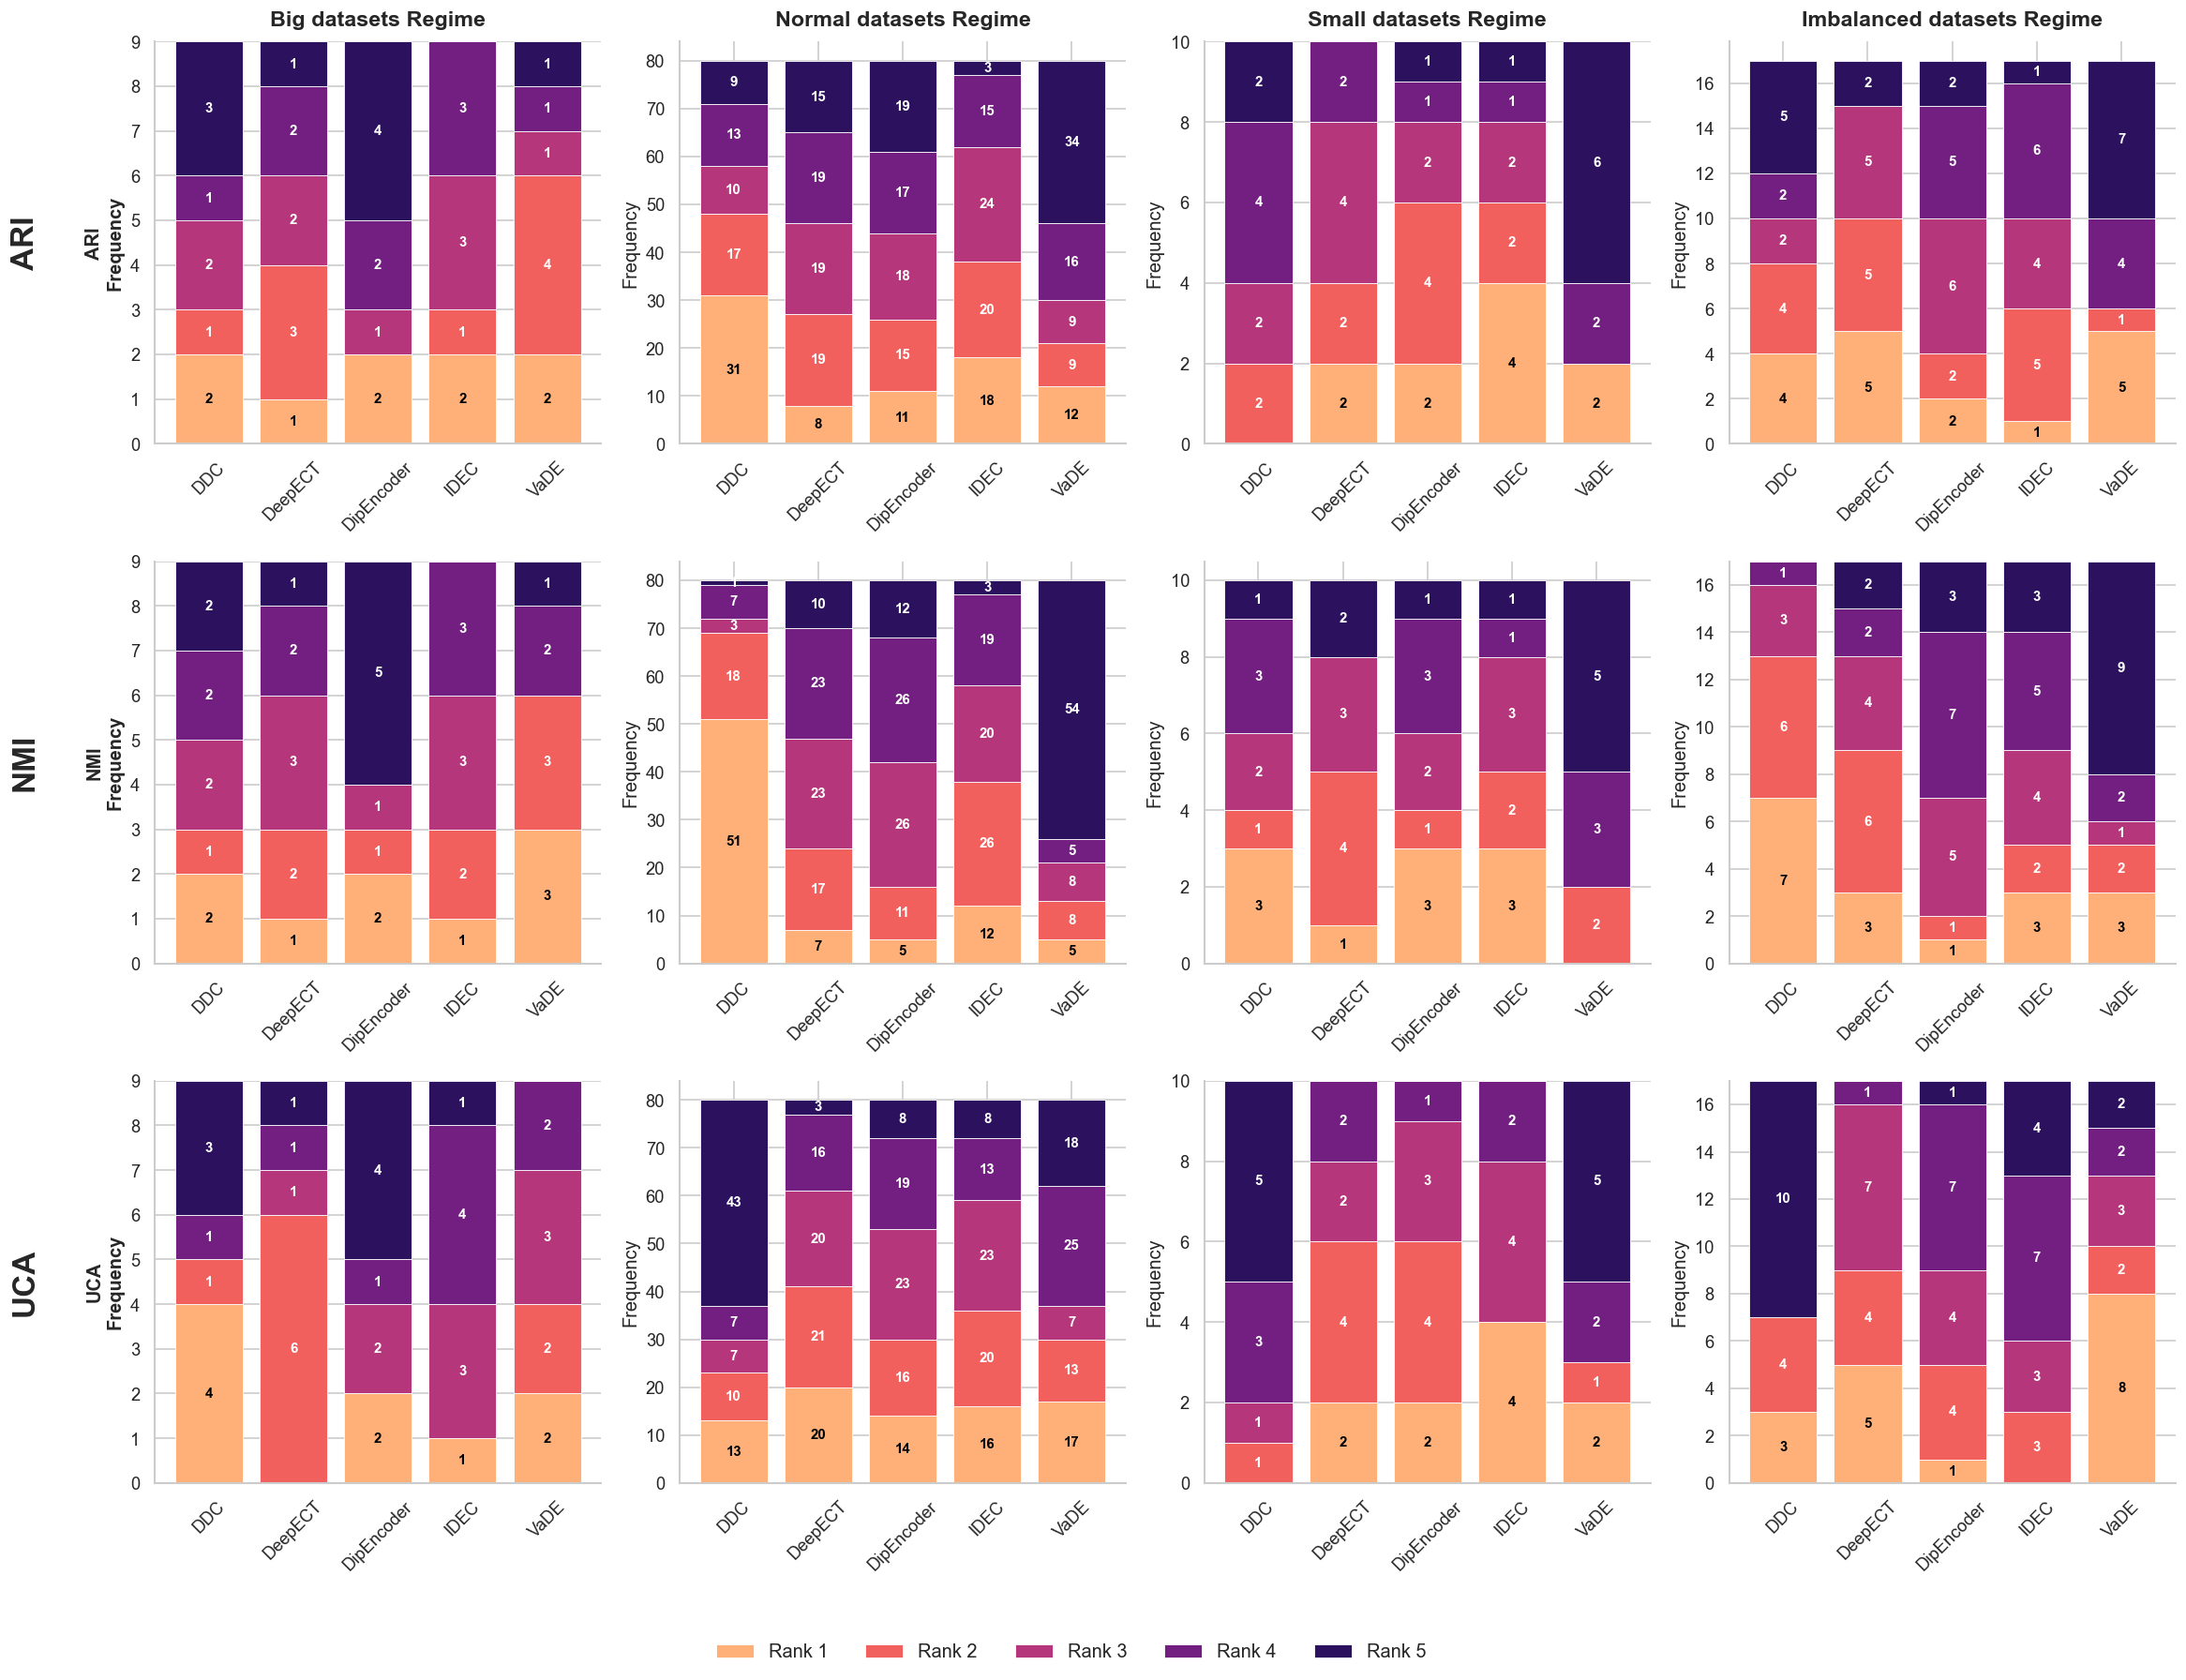

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_mega_rankings(mega_data):
    """
    mega_data: {
        'ARI': {'Normal': {...}, 'Big': {...}, ...},
        'NMI': {'Normal': {...}, 'Big': {...}, ...},
        'UCA': {'Normal': {...}, 'Big': {...}, ...}
    }
    """
    sns.set_theme(style="whitegrid")
    
    metrics = list(mega_data.keys())
    regimes = list(mega_data[metrics[0]].keys())
    
    # Get unique algos and ranks from the first available entry
    first_entry = mega_data[metrics[0]][regimes[0]]
    algos = sorted(first_entry.keys())
    ranks = sorted(list(first_entry[algos[0]].keys()))
    
    # Warm-to-cool palette: Rank 1 is bright/warm
    colors = sns.color_palette("magma_r", len(ranks))

    fig, axes = plt.subplots(len(metrics), len(regimes), 
                             figsize=(20, 5 * len(metrics)), 
                             squeeze=False)

    for row_idx, metric_name in enumerate(metrics):
        for col_idx, regime_name in enumerate(regimes):
            ax = axes[row_idx, col_idx]
            counts = mega_data[metric_name][regime_name]
            bottom = [0] * len(algos)

            for j, rk in enumerate(ranks):
                vals = [counts.get(a, {}).get(rk, 0) for a in algos]
                
                ax.bar(algos, vals, bottom=bottom, color=colors[j], 
                       label=f"Rank {rk}", edgecolor='white', linewidth=0.5)
                
                # Contrast logic: Dark text for bright Rank 1, White for others
                text_color = "black" if j == 0 else "white"
                
                for k, val in enumerate(vals):
                    if val > 0:
                        ax.text(k, bottom[k] + val/2, str(val), 
                                ha='center', va='center', color=text_color, 
                                fontweight='bold', fontsize=9)
                
                for k in range(len(algos)):
                    bottom[k] += vals[k]

            # Individual plot styling
            if row_idx == 0:
                ax.set_title(f"{regime_name} Regime", fontweight='bold', fontsize=14, pad=10)
            
            if col_idx == 0:
                ax.set_ylabel(f"{metric_name}\nFrequency", fontweight='bold', fontsize=12)
            else:
                ax.set_ylabel("Frequency")

            ax.tick_params(axis='x', rotation=45)
            sns.despine(ax=ax, left=False)

    # Add big row titles on the far left for metric identification
    for ax, row_label in zip(axes[:,0], metrics):
        ax.annotate(row_label, xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 25, 0),
                    xycoords=ax.yaxis.label, textcoords='offset points',
                    size=20, ha='right', va='center', fontweight='bold', rotation=90)

    # Global legend at the very bottom
    handles, labels = axes[0,0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(ranks), 
               bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=12)
    
    plt.tight_layout(rect=[0.02, 0.03, 1, 0.98])
    plt.show()

plot_mega_rankings(mega_data)

In [10]:
mega_data = {"ARI":{
    #"All datasets": get_results(df_agg_all)[1],
    "Big datasets": get_results(df_agg_big,metric="ARI")[1],
    "Normal datasets": get_results(df_agg_normal,metric="ARI")[1],
    "Small datasets": get_results(df_agg_small,metric="ARI")[1],
    "Imbalanced datasets": get_results(df_agg_imbalanced,metric="ARI")[1],
},
             "NMI":
{
    #"All datasets": get_results(df_agg_all)[1],
    "Big datasets": get_results(df_agg_big,metric="NMI")[1],
    "Normal datasets": get_results(df_agg_normal,metric="NMI")[1],
    "Small datasets": get_results(df_agg_small,metric="NMI")[1],
    "Imbalanced datasets": get_results(df_agg_imbalanced,metric="NMI")[1],
},
             "UCA": {
    #"All datasets": get_results(df_agg_all)[1],
    "Big datasets": get_results(df_agg_big,metric="UCA")[1],
    "Normal datasets": get_results(df_agg_normal,metric="UCA")[1],
    "Small datasets": get_results(df_agg_small,metric="UCA")[1],
    "Imbalanced datasets": get_results(df_agg_imbalanced,metric="UCA")[1],
}
}

Average relative performance vs dataset mean:
IDEC          0.2276
VaDE          0.0889
DeepECT       0.0376
DDC          -0.0830
DipEncoder   -0.2710
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.2372
IDEC          0.0794
DeepECT      -0.0447
DipEncoder   -0.0910
DDC          -0.1809
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.1643
DeepECT       0.0083
DipEncoder    0.0011
IDEC         -0.0033
DDC          -0.1705
dtype: float64
Average relative performance vs dataset mean:
VaDE          0.6281
DDC          -0.0179
DeepECT      -0.0542
IDEC         -0.1767
DipEncoder   -0.3793
dtype: float64
Average relative performance vs dataset mean:
IDEC          0.1383
VaDE          0.1054
DeepECT       0.0236
DDC          -0.0169
DipEncoder   -0.2503
dtype: float64
Average relative performance vs dataset mean:
DDC           0.3592
IDEC          0.0042
DeepECT      -0.0098
DipEncoder   -0.0884
VaDE         -0.2652
dtype: float64
Aver

In [11]:
def get_avg_rankings(data):
    results = {}

    for regime, algos in data.items():
        results[regime] = {}
        for algo, counts in algos.items():
            # Sum of (Rank * Count)
            total_weighted_rank = sum(rank * count for rank, count in counts.items())
            # Total number of datasets for this algorithm
            total_datasets = sum(counts.values())
            
            avg_rank = total_weighted_rank / total_datasets
            results[regime][algo] = round(avg_rank, 2)

    # Print results to copy into your LaTeX table
    for regime, algos in results.items():
        print(f"--- {regime} ---")
        for algo, rank in algos.items():
            print(f"{algo}: {rank}")

get_avg_rankings(regime_rankings)

--- Big datasets ---
DeepECT: 2.89
DDC: 3.22
IDEC: 2.78
VaDE: 2.44
DipEncoder: 3.67
--- Normal datasets ---
DDC: 2.4
VaDE: 3.64
IDEC: 2.56
DeepECT: 3.17
DipEncoder: 3.23
--- Small datasets ---
VaDE: 4.0
DeepECT: 2.6
DDC: 3.6
DipEncoder: 2.5
IDEC: 2.3
--- Imbalanced datasets ---
DeepECT: 2.35
DDC: 3.0
DipEncoder: 3.18
IDEC: 3.06
VaDE: 3.41


/var/folders/3_/msjl2wb51gz9nk6lr_j5k4xw0000gn/T/ipykernel_3844/2316973976.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_processed_data[metric], x='algo', y='rel_imp_pct', order=fixed_order,
/var/folders/3_/msjl2wb51gz9nk6lr_j5k4xw0000gn/T/ipykernel_3844/2316973976.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_processed_data[metric], x='algo', y='rel_imp_pct', order=fixed_order,
/var/folders/3_/msjl2wb51gz9nk6lr_j5k4xw0000gn/T/ipykernel_3844/2316973976.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=

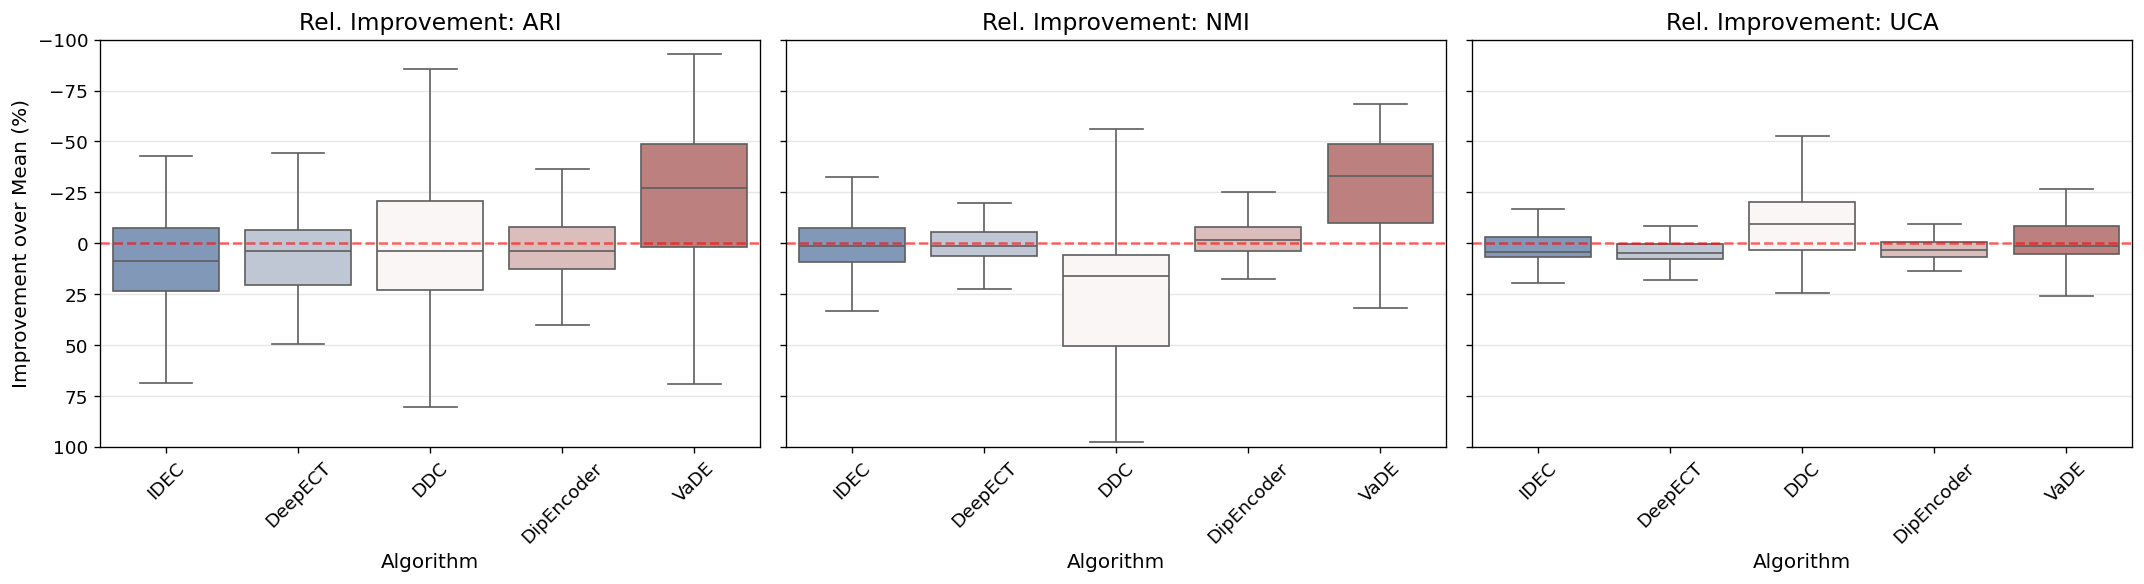

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_triple_relative_impact_fixed(df, mode='best'):
    metrics = ['metrics.ARI_mean', 'metrics.NMI_mean', 'metrics.UCA_mean']
    all_processed_data = {}
    
    # 1. Pre-calculate all relative improvements to find global Y-limits
    for metric in metrics:
        if mode == 'best':
            data = df.groupby(['did', 'algo'])[metric].max().reset_index()
        else:
            data = df.groupby(['did', 'algo'])[metric].mean().reset_index()

        means = data.groupby('did')[metric].mean().rename('d_mean')
        data = data.join(means, on='did')
        data['rel_imp_pct'] = ((data[metric] - data['d_mean']) / (data['d_mean'] + 1e-6)) * 100
        all_processed_data[metric] = data

    # Find global range (excluding extreme outliers for a clean view)
    combined_pcts = pd.concat([d['rel_imp_pct'] for d in all_processed_data.values()])
    y_min = 100 # Lower 1%
    y_max = -100 # Upper 99%

    # 2. Establish fixed order based on ARI median
    ref_data = all_processed_data['metrics.ARI_mean']
    fixed_order = ref_data.groupby('algo')['rel_imp_pct'].median().sort_values(ascending=False).index

    # 3. Plotting
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    
    for i, metric in enumerate(metrics):
        metric_name = metric.split('.')[1].split('_')[0]
        sns.boxplot(data=all_processed_data[metric], x='algo', y='rel_imp_pct', order=fixed_order, 
                    palette='vlag', showfliers=False, ax=axes[i])
        
        axes[i].axhline(0, color='red', linestyle='--', alpha=0.6)
        axes[i].set_title(f"Rel. Improvement: {metric_name}", fontsize=14)
        axes[i].set_ylim(y_min, y_max) # Explicitly force the same range
        axes[i].set_ylabel("Improvement over Mean (%)" if i == 0 else "")
        axes[i].set_xlabel("Algorithm")
        axes[i].grid(axis='y', alpha=0.3)
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()
plot_triple_relative_impact_fixed(df_agg_all, mode='mean')

                     ARI       NMI       UCA
Silhouette     -0.167167 -0.190117 -0.134744
Davies-Bouldin  0.180165  0.175922  0.138916


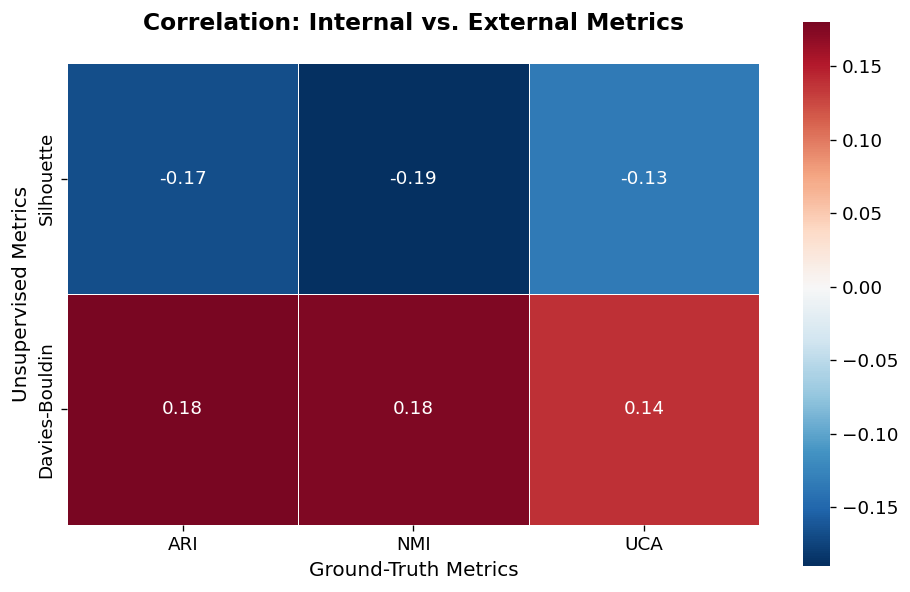

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_metric_correlation_clean(df):
    # 1. Define original names
    external_orig = ['metrics.ARI_mean', 'metrics.NMI_mean', 'metrics.UCA_mean']
    internal_orig = ['metrics.Silhouette_mean', 'metrics.Davies-Bouldin_mean']
    all_metrics = external_orig + internal_orig
    
    # 2. Calculate Spearman Correlation
    corr_matrix = df[all_metrics].corr(method='spearman')
    cross_corr = corr_matrix.loc[internal_orig, external_orig]

    # 3. Clean the names for the plot
    # Logic: take part after '.', then remove '_mean'
    clean_map = {name: name.split('.')[-1].replace('_mean', '') for name in all_metrics}
    
    cross_corr.index = [clean_map[name] for name in internal_orig]
    cross_corr.columns = [clean_map[name] for name in external_orig]
    print(cross_corr)
    # 4. Plot
    plt.figure(figsize=(8, 6))
    sns.heatmap(cross_corr, 
                annot=True, 
                fmt=".2f", 
                cmap='RdBu_r', 
                center=0, 
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .8})

    plt.title("Correlation: Internal vs. External Metrics", fontweight='bold', pad=20)
    plt.xlabel("Ground-Truth Metrics")
    plt.ylabel("Unsupervised Metrics")
    plt.tight_layout()
    plt.show()

    return cross_corr
corr_results = plot_metric_correlation_clean(df_agg_all)

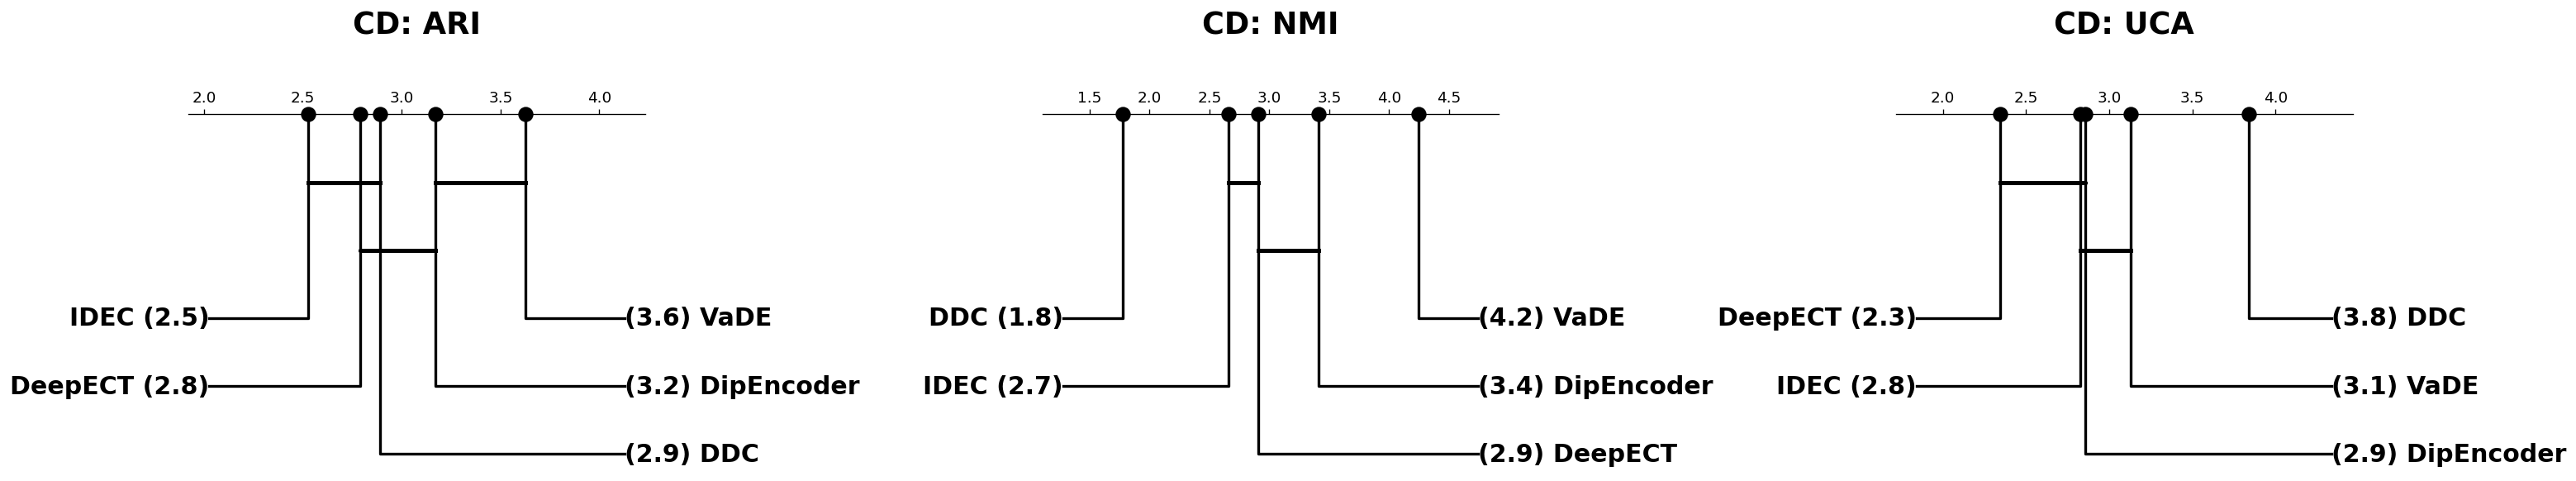

In [14]:
import pandas as pd
import scikit_posthocs as sp
import matplotlib.pyplot as plt

def plot_triple_cd_diagram_bw_final(df, mode='mean'):
    metrics = ['metrics.ARI_mean', 'metrics.NMI_mean', 'metrics.UCA_mean']
    
    # 1x3 layout: Increased figsize to (26, 5) to accommodate larger text
    fig, axes = plt.subplots(1, 3, figsize=(26, 5)) 
    
    # SIGNIFICANTLY LARGER FONT SIZES
    # 's' defines marker area (increased for visibility)
    marker_props = {'s': 100, 'edgecolor': 'black'}
    label_props = {'fontsize': 18, 'fontweight': 'bold'}
    crossbar_props = {'linewidth': 3.0}
    elbow_props = {'linewidth': 2.0}

    for i, metric in enumerate(metrics):
        # 1. Aggregate
        if mode == 'best':
            data = df.groupby(['did', 'algo'])[metric].max().reset_index()
        else:
            data = df.groupby(['did', 'algo'])[metric].mean().reset_index()

        # 2. Pivot
        pivot = data.pivot(index='did', columns='algo', values=metric).dropna()
        num_algos = len(pivot.columns)

        # 3. Calculate Mean Ranks
        avg_ranks = pivot.rank(axis=1, ascending=False).mean()

        # 4. Significance Matrix
        sig_matrix = sp.posthoc_nemenyi_friedman(pivot)

        # 5. Plotting
        clean_name = metric.split('.')[1].split('_')[0]
        # Bigger Title
        axes[i].set_title(f"CD: {clean_name}", fontweight='bold', fontsize=22, y=1.15)
        
        sp.critical_difference_diagram(
            avg_ranks, 
            sig_matrix, 
            ax=axes[i],
            color_palette=['black'] * num_algos,  # Forces B&W and avoids TypeError
            marker_props=marker_props,
            label_props=label_props,
            crossbar_props=crossbar_props,
            elbow_props=elbow_props,
            text_h_margin=0.5 # Increased margin for larger labels
        )

    plt.tight_layout()
    plt.show()

# Execution
plot_triple_cd_diagram_bw_final(df_agg_all, mode='mean')

In [ ]:
def get_config_stability_all(df):
    # Specify the mean columns to calculate sensitivity for
    metrics = ["metrics.UCA_mean", "metrics.ARI_mean", "metrics.NMI_mean"]
    
    stability = (
        # 1. Group by algorithm and dataset
        df.groupby(["algo", "did"])[metrics]
        # 2. Calculate std across all configurations in that group
        .std()
        .reset_index()
        # 3. Group by algorithm and average those stds across all datasets
        .groupby("algo")[metrics]
        .mean()
        .sort_values("metrics.UCA_mean")
    )
    
    # Optional: Rename columns to be explicit
    stability.columns = ["UCA_config_sens", "ARI_config_sens", "NMI_config_sens"]
    return stability

def get_seed_stability(df):
    # Use double brackets [[]] to pass a list and avoid the tuple error
    metrics_std = ["metrics.UCA_std", "metrics.ARI_std", "metrics.NMI_std"]
    
    stability = (
        df.groupby("algo")[metrics_std]
        .mean()
        .sort_values("metrics.UCA_std")
    )
    return stability

# Execute and Print
config_stability = get_config_stability_all(df_agg_all)
print("Config Sensitivity (Average SD across configurations):")
print(config_stability.round(4))

seed_stability = get_seed_stability(df_agg_all)
print("\nSeed Stability (Average SD across random seeds):")
print(seed_stability.round(4))

In [ ]:
HP_COLUMNS = [
    "config.pretrain.lr",
    "config.clustering.lr",
    "config.batch_size",
    "config.early_stopping",
    "config.arch",
    "config.bottleneck_dim"
]

drop_cols = [
    "config.data.input_dim", "config.data.n_clusters",
    "config.nn_type", "config.clustering.epochs", "config.pretrain.epochs"
]

df_agg_hp = df_agg_all[[c for c in df_agg_all.columns if c.startswith("config.")]].copy()
df_agg_hp = df_agg_hp.drop(columns=drop_cols)

df_agg_hp["config.arch"]          = df_agg_hp["config.arch"].apply(ast.literal_eval).apply(len)
df_agg_hp["config.early_stopping"] = df_agg_hp["config.early_stopping"].apply(lambda x: 1 if x else 0)
df_agg_hp                          = df_agg_hp.astype(float)

df_agg_hp["algo"]        = df_agg_all["algo"].values
df_agg_hp["performance"] = df_agg_all["metrics.ARI_mean"].values

df_agg_hp.head()

In [ ]:
def run_importance(df, algo_name, performance_col="performance"):
    algo_df = df[df["algo"] == algo_name].copy()
    X = algo_df[HP_COLUMNS].astype(float).to_numpy()
    Y = algo_df[performance_col].astype(float).to_numpy()

    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X, Y)
    explainer  = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X)

    return pd.DataFrame({
        "hp": HP_COLUMNS,
        "importance": np.abs(shap_values).mean(axis=0),
        "std": np.abs(shap_values).std(axis=0),
    }).sort_values("importance", ascending=False)



shap_cache = {}
all_importances = {}

for algo in df_agg_hp["algo"].unique():
    algo_df = df_agg_hp[df_agg_hp["algo"] == algo].copy().reset_index(drop=True)
    X = algo_df[HP_COLUMNS].astype(float)
    Y = algo_df["performance"].astype(float)

    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X, Y)
    explainer = shap.TreeExplainer(rf)

    shap_cache[algo] = {
        "rf":          rf,
        "explainer":   explainer,
        "shap_values": explainer.shap_values(X),
        "explanation": explainer(X),
        "X":           X,
        "Y":           Y,
    }
    all_importances[algo] = run_importance(df_agg_hp, algo)

print("Cached algos:", list(shap_cache.keys()))

In [ ]:
# Run this cell and paste the output
for algo, cache in shap_cache.items():
    sv = cache["shap_values"]
    Y  = cache["Y"]
    print(f"\n{'='*40}")
    print(f"ALGO: {algo}")
    print(f"  n_samples      : {len(Y)}")
    print(f"  shap_values shape: {sv.shape}")
    print(f"  performance    : mean={Y.mean():.4f}  std={Y.std():.4f}  min={Y.min():.4f}  max={Y.max():.4f}")
    print(f"  top HP         : {all_importances[algo].iloc[0]['hp']}  (importance={all_importances[algo].iloc[0]['importance']:.4f})")
    print(f"  bottom HP      : {all_importances[algo].iloc[-1]['hp']}  (importance={all_importances[algo].iloc[-1]['importance']:.4f})")
    print(f"\n  Full importance table:")
    print(all_importances[algo].to_string(index=False))

In [ ]:
# 1. Define the metrics we want to aggregate
metric_cols = [
    'metrics.ARI', 'metrics.NMI', 'metrics.UCA', 
    'metrics.Davies_Bouldin', 'metrics.Silhouette', 'time_taken'
]

# 2. Group by 'did' (and 'algo' if you want to keep it) and aggregate
df_kmeans_agg = df_kmeans.groupby(['did', 'algo'])[metric_cols].agg(['mean', 'std'])

# 3. Flatten the multi-index columns (e.g., ('metrics.ARI', 'mean') -> 'metrics.ARI_mean')
df_kmeans_agg.columns = [f"{col[0]}_{col[1]}" for col in df_kmeans_agg.columns]

# 4. Reset index to bring 'did' and 'algo' back as regular columns
df_kmeans_agg = df_kmeans_agg.reset_index()

# Optional: Clean up names to match your deep clustering dataframe format
# df_kmeans_agg.columns = [c.replace('metrics.', '') for c in df_kmeans_agg.columns]

print(df_kmeans_agg.head())

# Save the aggregated version
df_kmeans_agg.to_parquet('kmeans_baselines_aggregated.parquet', index=False)

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_regime_benchmark_grid(df_deep, df_km):
    """
    Generates a 2-row, 3-column grid comparing Mean (Top) and Max (Bottom) 
    Relative Lift (%) over the KMeans baseline across data regimes.
    """
    # 1. Aesthetic Setup
    sns.set_theme(style="whitegrid")
    sns.set_context("talk", font_scale=1.1)
    
    # Kelly Palette
    kelly_colors = ["#E6194B", "#3CB44B", "#4363D8", "#F58231", "#911EB4"]
    
    metrics = ['ARI', 'NMI', 'UCA']  
    regime_order = ['Small', 'Normal', 'Big', 'Imbalanced']
    
    fig, axes = plt.subplots(2, 3, figsize=(28, 16), sharex=True)
    
    for row_idx, mode in enumerate(['mean', 'max']):
        m_cols = [f'metrics.{m}_mean' for m in metrics]
        if mode == 'mean':
            deep_agg = df_deep.groupby(['did', 'algo'])[m_cols].mean().reset_index()
            row_title = "EXPECTED LIFT (MEAN CONFIGURATION)"
        else:
            deep_agg = df_deep.groupby(['did', 'algo'])[m_cols].max().reset_index()
            row_title = "POTENTIAL LIFT (BEST CONFIGURATION)"

        km_ref = df_km[['did'] + [f'metrics.{m}_mean' for m in metrics]].copy()
        km_ref.columns = ['did', 'km_ARI', 'km_NMI', 'km_UCA']
        comp = pd.merge(deep_agg, km_ref, on='did')

        def get_regime(did):
            if did in imbalanced_ids: return 'Imbalanced'
            if did in small_ids: return 'Small'
            if did in normal_ids: return 'Normal'
            if did in big_ids: return 'Big'
            return 'Other'
        comp['regime'] = comp['did'].apply(get_regime)

        eps = 1e-6
        for col_idx, m in enumerate(metrics):
            lift_col = f'{m}_Rel_Lift'
            comp[lift_col] = ((comp[f'metrics.{m}_mean'] - comp[f'km_{m}']) / (comp[f'km_{m}'] + eps)) * 100
            
            ax = axes[row_idx, col_idx]
            sns.boxplot(
                data=comp, x='regime', y=lift_col, hue='algo',
                order=regime_order, palette=kelly_colors, 
                showfliers=False, linewidth=2.5, ax=ax
            )
            
            ax.axhline(0, color='black', linestyle='--', linewidth=2, alpha=0.8)
            ax.set_ylim(-150, 250) 
            
            # --- TICK SIZE & DUPLICATION UPDATES ---
            # Force labels on both rows even with sharex=True
            ax.tick_params(axis='x', labelbottom=True, labelsize=20) 
            ax.tick_params(axis='y', labelsize=18)
            # ----------------------------------------

            if row_idx == 0:
                ax.set_title(f"$\Delta$ {m} (%) - {row_title}", fontsize=22, fontweight='bold', pad=20)
                ax.set_xlabel("") # Keep empty since labels are duplicated below
            else:
                ax.set_title(f"$\Delta$ {m} (%) - {row_title}", fontsize=22, fontweight='bold', pad=20)
                ax.set_xlabel("Data Regime", fontsize=22, fontweight='bold')
            
            ax.set_ylabel("Rel. Improvement (%)", fontsize=18, fontweight='bold')
            
            if row_idx == 0 and col_idx == 1:
                ax.legend(title='Algorithm', bbox_to_anchor=(0.5, 1.25), loc='center', ncol=5, frameon=True, fontsize=18)
            else:
                ax.get_legend().remove()

    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

# Execution
plot_regime_benchmark_grid(df_agg_all, df_kmeans_agg)